In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm

R = 2.0
N_PMT = 40
r = 0.1
a = 0.5
Y = 10_000
E_TRUE = 1.0
POSITION_TRUE = np.array([0.35, -0.25, 0.45])
SEED = 2026

g++ not available, if using conda: `conda install gxx`


In [2]:
def generate_positions(R=R, N=N_PMT):
    i = np.arange(N)
    z = R * (1 - 2 * (i + 0.5) / N)
    phi = i * np.pi * (3 - np.sqrt(5))
    rho = np.sqrt(R**2 - z**2)
    return np.column_stack((rho * np.cos(phi), rho * np.sin(phi), z))

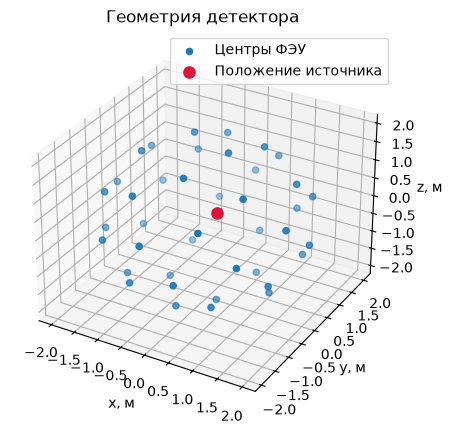

In [3]:
pmt_positions = generate_positions()

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(*pmt_positions.T, s=20, label="Центры ФЭУ")
ax.scatter(*POSITION_TRUE, color="crimson", s=65, label="Положение источника")
ax.set(xlabel="x, м", ylabel="y, м", zlabel="z, м", title="Геометрия детектора")
ax.legend()
plt.show()

In [4]:
def simulate_event(E, position, seed=SEED):
    rng = np.random.default_rng(seed)
    position = np.asarray(position, dtype=float)
    if E <= 0 or np.linalg.norm(position) >= R:
        raise ValueError("Энергия должна быть положительной, источник — внутри сферы")

    n_photons = int(round(Y * E))
    phi = rng.uniform(0.0, 2 * np.pi, n_photons)
    cos_theta = rng.uniform(-1.0, 1.0, n_photons)
    sin_theta = np.sqrt(1 - cos_theta**2)
    directions = np.column_stack((
        sin_theta * np.cos(phi), sin_theta * np.sin(phi), cos_theta
    ))

    b = directions @ position
    t = -b + np.sqrt(b**2 + R**2 - np.dot(position, position))
    points = position[None, :] + t[:, None] * directions

    distances2 = np.sum(
        (points[:, None, :] - pmt_positions[None, :, :])**2, axis=2
    )
    nearest = np.argmin(distances2, axis=1)
    is_hit = distances2[np.arange(n_photons), nearest] <= r**2
    hits = np.bincount(nearest[is_hit], minlength=N_PMT)
    charges = rng.poisson(a * hits)
    return charges, hits

In [5]:
observed, hits = simulate_event(E_TRUE, POSITION_TRUE)
print("Истинная энергия:", E_TRUE, "МэВ")
print("Истинная позиция:", POSITION_TRUE, "м")
print("Попаданий на ФЭУ:", hits.sum())
print("Наблюдаемый полный заряд:", observed.sum(), "ф.э.")
print("Массив зарегистрированных зарядов:", observed)

Истинная энергия: 1.0 МэВ
Истинная позиция: [ 0.35 -0.25  0.45] м
Попаданий на ФЭУ: 274
Наблюдаемый полный заряд: 125 ф.э.
Массив зарегистрированных зарядов: [6 4 4 5 0 3 2 3 9 5 7 5 2 9 1 5 2 1 6 1 0 6 2 6 2 0 7 1 1 0 5 3 0 1 0 0 4
 3 1 3]


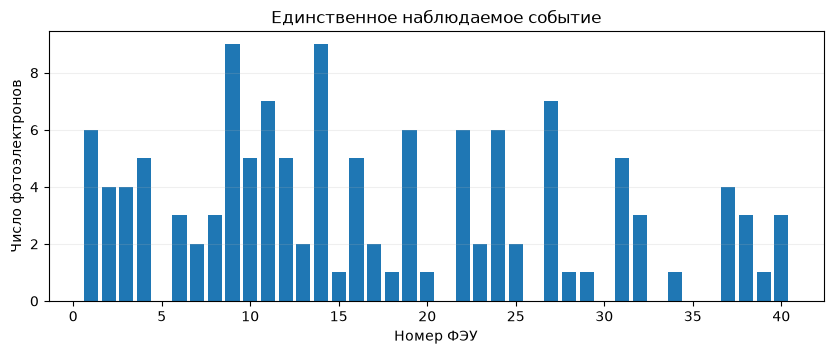

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(np.arange(1, N_PMT + 1), observed)
ax.set(xlabel="Номер ФЭУ", ylabel="Число фотоэлектронов",
       title="Единственное наблюдаемое событие")
ax.grid(axis="y", alpha=0.2)
plt.show()

In [7]:
def expected_charge_numpy(E, position):
    s = np.asarray(position)
    normals = pmt_positions / R
    distance = np.linalg.norm(pmt_positions - s[None, :], axis=1)
    incidence = R - normals @ s
    p = r**2 * incidence / (4.0 * distance**3)
    return a * Y * E * p

In [8]:
mu_true = expected_charge_numpy(E_TRUE, POSITION_TRUE)
print("Ожидаемый суммарный заряд по аналитической модели:", round(mu_true.sum(), 2))
print("Зарегистрированный суммарный заряд:", observed.sum())
mu_center = expected_charge_numpy(1.0, np.zeros(3))

Ожидаемый суммарный заряд по аналитической модели: 125.12
Зарегистрированный суммарный заряд: 125


In [9]:
with pm.Model() as reconstruction_model:
    energy = pm.LogNormal("energy", mu=0.0, sigma=0.8)
    x = pm.Uniform("x", lower=-1.0, upper=1.0)
    y = pm.Uniform("y", lower=-1.0, upper=1.0)
    z = pm.Uniform("z", lower=-1.0, upper=1.0)

    position = pm.math.stack([x, y, z])
    normals = pmt_positions / R
    difference = pmt_positions - position[None, :]
    d = pm.math.sqrt(pm.math.sum(difference**2, axis=1))
    incidence = R - pm.math.sum(normals * position[None, :], axis=1)
    p = r**2 * incidence / (4.0 * d**3)
    mu = a * Y * energy * p
    alpha = mu / (a * (1.0 - p))

    pm.NegativeBinomial("q_observed", mu=mu, alpha=alpha, observed=observed)

    trace = pm.sample(
        draws=1000,
        tune=1000,
        chains=2,
        cores=1,
        target_accept=0.92,
        random_seed=42,
        progressbar=True,
        return_inferencedata=True
    )

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [energy, x, y, z]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 7 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


  Параметр |   Истина |   Медиана |              95% интервал
-----------------------------------------------------------------
    energy |    1.000 |     1.006 | [   0.806,    1.212]
         x |    0.350 |     0.668 | [   0.359,    0.939]
         y |   -0.250 |    -0.278 | [  -0.633,    0.055]
         z |    0.450 |     0.407 | [   0.124,    0.704]


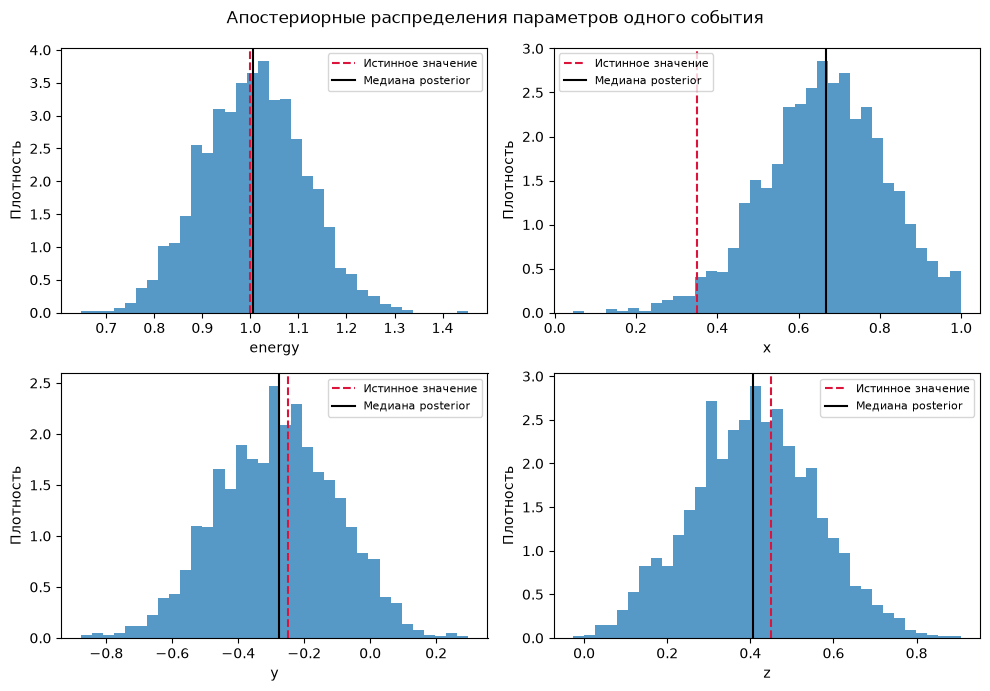

Число divergent transitions: 0


In [10]:
parameter_names = ["energy", "x", "y", "z"]
true_values = [E_TRUE, *POSITION_TRUE]
posterior_samples = {}

print(f"{'Параметр':>10} | {'Истина':>8} | {'Медиана':>9} | {'95% интервал':>25}")
print("-" * 65)
for name, true in zip(parameter_names, true_values):
    samples = np.asarray(trace.posterior[name]).reshape(-1)
    posterior_samples[name] = samples
    lo, median, hi = np.quantile(samples, [0.025, 0.5, 0.975])
    print(f"{name:>10} | {true:8.3f} | {median:9.3f} | [{lo:8.3f}, {hi:8.3f}]")

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, name, truth in zip(axes.flat, parameter_names, true_values):
    ax.hist(posterior_samples[name], bins=35, density=True, alpha=0.75)
    ax.axvline(truth, color="crimson", linestyle="--", label="Истинное значение")
    ax.axvline(np.median(posterior_samples[name]), color="black", label="Медиана posterior")
    ax.set(xlabel=name, ylabel="Плотность")
    ax.legend(fontsize=8)
plt.suptitle("Апостериорные распределения параметров одного события")
plt.tight_layout()
plt.show()

print("Число divergent transitions:",
      int(np.asarray(trace.sample_stats["diverging"]).sum()))

Sampling: [q_observed]


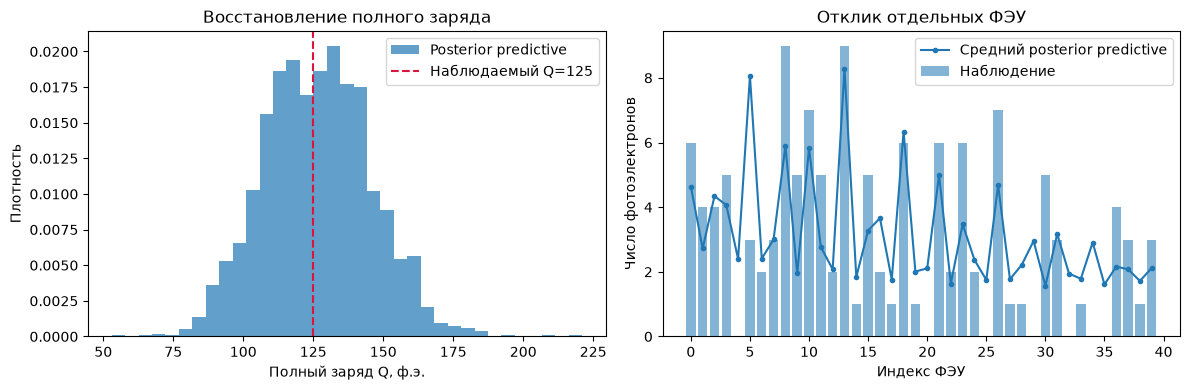

Наблюдаемый суммарный заряд: 125
Средний предсказанный суммарный заряд: 126.35


In [11]:
with reconstruction_model:
    predictive = pm.sample_posterior_predictive(
        trace,
        var_names=["q_observed"],
        predictions=True,
        random_seed=43,
        progressbar=False
    )

q_pred = np.asarray(predictive.predictions["q_observed"]).reshape(-1, N_PMT)
q_total_pred = q_pred.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(q_total_pred, bins=35, density=True, alpha=0.7,
             label="Posterior predictive")
axes[0].axvline(observed.sum(), color="crimson", linestyle="--",
                label=f"Наблюдаемый Q={observed.sum()}")
axes[0].set(xlabel="Полный заряд Q, ф.э.", ylabel="Плотность",
            title="Восстановление полного заряда")
axes[0].legend()
axes[1].bar(np.arange(N_PMT), observed, alpha=0.55, label="Наблюдение")
axes[1].plot(np.arange(N_PMT), q_pred.mean(axis=0), "o-", ms=3,
             label="Средний posterior predictive")
axes[1].set(xlabel="Индекс ФЭУ", ylabel="Число фотоэлектронов",
            title="Отклик отдельных ФЭУ")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Наблюдаемый суммарный заряд:", observed.sum())
print("Средний предсказанный суммарный заряд:", round(q_total_pred.mean(), 2))